In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
thu_muc_goc = Path.cwd()
if not (thu_muc_goc / "src").exists():
    thu_muc_goc = thu_muc_goc.parent
if str(thu_muc_goc) not in sys.path:
    sys.path.insert(0, str(thu_muc_goc))

from src.du_lieu import doc_du_lieu
from src.danh_gia import danh_gia_mo_hinh
from src.luu_ket_qua import luu_bang_ket_qua



In [2]:
train_data, test_data, phim = doc_du_lieu(thu_muc_goc)
print("Train:", train_data.shape)
print("Test:", test_data.shape)

Train: (800167, 4)
Test: (200042, 4)


In [3]:
from src.matrix_factorization import huan_luyen_mf, goi_y_mf
from src.luu_ket_qua import luu_mo_hinh, doc_mo_hinh

mo_hinh = huan_luyen_mf(
    train_data,
    tiem_an=50,
    lr=0.005,
    l2=0.02,
    epoch=15,
    random_state=42,
)

Epoch 1/15 | Online train RMSE: 0.9817
Epoch 2/15 | Online train RMSE: 0.9243
Epoch 3/15 | Online train RMSE: 0.9117
Epoch 4/15 | Online train RMSE: 0.9057
Epoch 5/15 | Online train RMSE: 0.9018
Epoch 6/15 | Online train RMSE: 0.8989
Epoch 7/15 | Online train RMSE: 0.8960
Epoch 8/15 | Online train RMSE: 0.8926
Epoch 9/15 | Online train RMSE: 0.8882
Epoch 10/15 | Online train RMSE: 0.8824
Epoch 11/15 | Online train RMSE: 0.8751
Epoch 12/15 | Online train RMSE: 0.8668
Epoch 13/15 | Online train RMSE: 0.8579
Epoch 14/15 | Online train RMSE: 0.8489
Epoch 15/15 | Online train RMSE: 0.8396


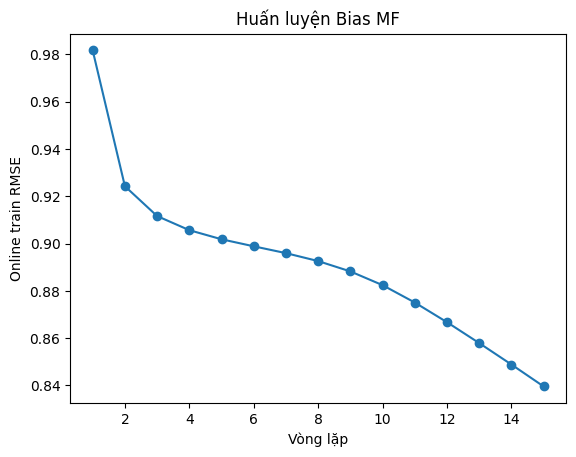

In [4]:
lich_su = mo_hinh["lich_su"]
plt.plot(range(1, len(lich_su) + 1), lich_su, marker="o")
plt.xlabel("Vòng lặp")
plt.ylabel("Online train RMSE")
plt.title("Huấn luyện Bias MF")
plt.show()

In [5]:
bang_goi_y = goi_y_mf(mo_hinh, ma_nguoi_dung=1, so_phim=10)
display(bang_goi_y.merge(phim, on="movie_id", how="left"))

,movie_id,score,title,genres
0,2905,4.839647,Sanjuro (1962),Action|Adventure
1,318,4.749995,"Shawshank Redemption, The (1994)",Drama
2,2019,4.708200,Seven Samurai (The Magnificent Seven) (Shichin...,Action|Drama
3,922,4.642368,Sunset Blvd. (a.k.a. Sunset Boulevard) (1950),Film-Noir
4,1178,4.642024,Paths of Glory (1957),Drama|War
5,2360,4.640775,"Celebration, The (Festen) (1998)",Drama
6,1148,4.634130,"Wrong Trousers, The (1993)",Animation|Comedy
7,1262,4.630872,"Great Escape, The (1963)",Adventure|War
8,904,4.623852,Rear Window (1954),Mystery|Thriller
9,912,4.622200,Casablanca (1942),Drama|Romance|War


In [6]:
duong_dan = thu_muc_goc / "models/mo_hinh_mf.joblib"
luu_mo_hinh(mo_hinh, duong_dan)
mo_hinh_da_luu = doc_mo_hinh(duong_dan)
print("Đã lưu và đọc lại:", duong_dan.name)

Đã lưu và đọc lại: mo_hinh_mf.joblib


In [7]:
ket_qua, chi_tiet = danh_gia_mo_hinh(goi_y_mf, mo_hinh_da_luu, test_data, k=10)
bang_ket_qua = pd.DataFrame([ket_qua])
bang_ket_qua.insert(0, "model", "Bias MF")
display(bang_ket_qua)
luu_bang_ket_qua(bang_ket_qua, thu_muc_goc / "reports/tables/thu_nghiem_mf.csv")
luu_bang_ket_qua(chi_tiet, thu_muc_goc / "reports/chi_tiet/thu_nghiem_mf.csv")

,model,Precision@10,Recall@10,F1@10,NDCG@10,evaluated_users,evaluated_rows,dropped_rows
0,Bias MF,0.074091,0.039128,0.041667,0.081582,5994,200016,26
